# Python Basics for Labs A and B

## Changelog (Nov 2026)
1. **Uncertainty formatting** – parameters on the plot are shown as `value ± error` with the error rounded to `sig_digits` *significant figures* (default 2) and the value rounded to the same decimal place; very large/small values get a common ×10ⁿ factor. (Before, `sig_digits` meant a fixed number of decimal places, so e.g. 1e-7 printed as 0.00000.)
2. **Fit-validity check** – iminuit warnings stay silenced, but if the minimum is **not valid** a clear warning is printed with the reason (call limit, not converged, parameter at limit, bad covariance). Nothing is printed for a good fit.
3. **Stable derivative** – `Chi2Reg` uses a central difference for `df/dx` with a step scaled to the data range; data is sorted by x automatically. `np.sum` replaces Python `sum`; the deprecated `make_func_code` was removed; list inputs now work in both regressors.
4. **New: `predict(opt, x)`** – interpolation / extrapolation returning `(y, σ_y)`, with σ propagated from the full covariance matrix (`σ² = J C Jᵀ`). `show()` gained `x_range=(xmin, xmax)` (extrapolated part drawn dashed) and `show_band=True` (±1σ band).
5. **New: `inverse_predict(opt, y_target)`** – finds all x in a range where `f(x) = y_target`, with `σ_x = √(σ_f² + σ_target²) / |f'(x)|`.

See the section *Interpolation, extrapolation and inverse prediction* below for usage.

## Required Installs and Imports

In [1]:
!pip install -q matplotlib iminuit scikit-learn


[notice] A new release of pip is available: 24.0 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# general python packages for classes, warning ,etc.
from abc import ABC, abstractmethod
from typing import Annotated
import warnings

# numpy for numeric calcualtion
import numpy as np

# pandas for data manipulation
import pandas as pd

# matplotlib for plotting
import matplotlib.pyplot as plt
from matplotlib.offsetbox import AnchoredText

# iminuit as the minimizer
from iminuit import Minuit, describe

# sklearn for goodness estimation methods
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# scipy root finder used by inverse_predict
from scipy.optimize import brentq

from scipy.stats.distributions import chi2 #this is for chi2 statistics there is likely a way to calculate (in particular p-value) from numpy or sklearn ...

%matplotlib inline
# iminuit warnings are silenced; an invalid fit is still reported by check_fit()
warnings.simplefilter("ignore")

## Class Definitions

We define here a base regressor class that has the responsibility to provide iminuit with the cost function value. It is also responsible to produce the goodness estimation and to plot the result via the show method.

All changes to the way the plots are presented should be modified here.

**Helpers defined here:**
- `fmt_pm(val, err, n=2)` – formats `value ± error` with the error rounded to `n` significant figures and the value rounded to the same digit (scientific factor for very large/small numbers).
- `check_fit(opt)` – prints a warning **only if** Minuit's minimum is not valid (returns `True/False`). It is called automatically by `show`, `predict` and `inverse_predict`.
- `reg.predict(opt, x_new)` – interpolation/extrapolation with uncertainty.
- `reg.inverse_predict(opt, y_target)` – solve `f(x) = y_target` for x, with uncertainty.

In [ ]:
def fmt_pm(val, err, n=2, latex=True):
    """
    Format "value ± error" for a lab report:
    the error is rounded to n significant figures and the value is rounded
    to the same decimal place. Very large/small numbers get a common
    power-of-ten factor, e.g. (6.59 ± 0.12)×10^8.
    latex=True  -> matplotlib mathtext string (used inside $...$ on plots)
    latex=False -> plain text for print()
    """
    pm, times = (" \\pm ", "\\times 10^{%d}") if latex else (" ± ", "×10^%d")
    val, err = float(val), float(err)
    if not np.isfinite(err) or err <= 0:
        return f"{val:.4g}{pm}{err:.2g}"
    ref = abs(val) if val != 0 else err
    e = int(np.floor(np.log10(ref)))
    if -2 <= e <= 3:          # "normal" sized numbers: no exponent
        e = 0
    s = 10.0 ** e
    d = max(0, n - 1 - int(np.floor(np.log10(err / s))))
    body = f"{val / s:.{d}f}{pm}{err / s:.{d}f}"
    return body if e == 0 else f"({body})" + times % e


def check_fit(optimizer) -> bool:
    """
    Prints a warning ONLY if Minuit did not reach a valid minimum.
    Returns True if the fit is valid.
    """
    if not optimizer.valid:
        fmin = optimizer.fmin
        reasons = []
        if fmin is not None:
            if fmin.has_reached_call_limit: reasons.append("call limit reached")
            if fmin.is_above_max_edm:       reasons.append("EDM above max (not converged)")
            if fmin.has_parameters_at_limit: reasons.append("parameter(s) at limit")
            if not fmin.has_accurate_covar: reasons.append("covariance not accurate")
            if fmin.has_made_posdef_covar:  reasons.append("covariance forced positive-definite")
        why = "; ".join(reasons) if reasons else "unknown reason"
        print(f"⚠ WARNING: fit minimum is NOT valid ({why}).\n"
              f"  Results/uncertainties are unreliable - try better initial guesses, "
              f"limits (opt.limits[...]) or call opt.migrad() again.")
        return False
    return True


class Regressor(ABC):
    """
    Abstract base class for regressors compatible with Iminuit.
    To edit the plotting of the graph, edit the show method.
    """

    @abstractmethod
    def __init__(self, model : callable, x : list, y: list, dx : list, dy : list)->None:
        pass

    #this part defines the calculations when the function is called
    @abstractmethod
    def __call__(self, *par)->float:
        pass

    # ------------------------------------------------------------------ #
    #  helpers                                                            #
    # ------------------------------------------------------------------ #
    def _prepare_data(self, x, y, dx, dy):
        """Convert to float arrays and sort all data by x (ascending)."""
        x = np.asarray(x, dtype=float)
        y = np.asarray(y, dtype=float)
        dx = np.zeros_like(x) if dx is None else np.broadcast_to(np.asarray(dx, dtype=float), x.shape).copy()
        dy = None if dy is None else np.broadcast_to(np.asarray(dy, dtype=float), x.shape).copy()
        order = np.argsort(x, kind="stable")
        if np.any(order != np.arange(x.size)):
            print("Note: data was not sorted by x - it has been sorted (x, y, dx, dy together).")
        self.x, self.y, self.dx = x[order], y[order], dx[order]
        self.dy = None if dy is None else dy[order]
        # step for numerical derivatives (central difference), scaled to the data
        span = np.ptp(self.x)
        self.h = 1e-6 * (span if span > 0 else max(np.max(np.abs(self.x)), 1.0))

    def dfdx(self, x, *par):
        """Numerical derivative df/dx using a central difference (error O(h^2))."""
        x = np.asarray(x, dtype=float)
        return (np.asarray(self.model(x + self.h, *par)) - np.asarray(self.model(x - self.h, *par))) / (2 * self.h)

    @staticmethod
    def _par_arrays(optimizer):
        p = np.array(optimizer.values, dtype=float)
        if optimizer.covariance is None:
            raise RuntimeError("No covariance matrix - run opt.migrad() (and opt.hesse()) first.")
        C = np.array(optimizer.covariance, dtype=float)
        return p, C

    # ------------------------------------------------------------------ #
    #  interpolation / extrapolation with uncertainty                     #
    # ------------------------------------------------------------------ #
    def predict(self, optimizer, x_new, rel_step=1e-6):
        """
        Evaluate the fitted model at x_new (inside the data range = interpolation,
        outside = extrapolation) and return (y, sigma_y).

        sigma_y is propagated from the FULL parameter covariance matrix C:
            sigma_y^2 = J C J^T ,   J_i = df/dp_i   (numerical, central difference)
        so correlations between parameters are taken into account.
        Note: this is the uncertainty of the fitted curve, not the spread of single measurements.
        """
        check_fit(optimizer)
        p, C = self._par_arrays(optimizer)
        scalar = np.ndim(x_new) == 0
        x_new = np.atleast_1d(np.asarray(x_new, dtype=float))
        y = np.asarray(self.model(x_new, *p), dtype=float) * np.ones_like(x_new)
        J = np.zeros((x_new.size, p.size))
        for i in range(p.size):
            if optimizer.fixed[i]:
                continue
            h = rel_step * max(abs(p[i]), 1e-12)
            dp = np.zeros_like(p); dp[i] = h
            J[:, i] = (np.asarray(self.model(x_new, *(p + dp))) - np.asarray(self.model(x_new, *(p - dp)))) / (2 * h)
        sigma = np.sqrt(np.einsum("ij,jk,ik->i", J, C, J))
        if scalar:
            return y[0], sigma[0]
        return y, sigma

    # ------------------------------------------------------------------ #
    #  inverse prediction: x such that f(x) = y_target                    #
    # ------------------------------------------------------------------ #
    def inverse_predict(self, optimizer, y_target, dy_target=0.0, x_range=None, n_scan=2000):
        """
        Find x where the fitted model equals y_target, with uncertainty.

        x_range  : (xmin, xmax) region to search. Default: the data range.
                   Give a wider range to extrapolate.
        dy_target: optional uncertainty on y_target itself.

        All solutions in x_range are returned (arrays x, sigma_x), because
        non-monotonic models can cross y_target more than once.

        Uncertainty (first-order propagation):
            sigma_x^2 = (sigma_f(x)^2 + dy_target^2) / (df/dx)^2
        where sigma_f(x) is the fit uncertainty from predict().
        """
        check_fit(optimizer)
        p = np.array(optimizer.values, dtype=float)
        lo, hi = (self.x.min(), self.x.max()) if x_range is None else map(float, x_range)
        g = lambda xx: np.asarray(self.model(xx, *p), dtype=float) - y_target
        grid = np.linspace(lo, hi, n_scan)
        gv = g(grid) * np.ones_like(grid)
        roots = []
        for k in range(n_scan - 1):
            if not (np.isfinite(gv[k]) and np.isfinite(gv[k + 1])):
                continue
            if gv[k] == 0:
                roots.append(grid[k])
            elif gv[k] * gv[k + 1] < 0:
                roots.append(brentq(lambda t: float(g(np.array([t]))[0]), grid[k], grid[k + 1], xtol=1e-14 * max(1.0, abs(grid[k]))))
        if gv[-1] == 0:
            roots.append(grid[-1])
        if not roots:
            print(f"No solution of f(x) = {y_target} found in [{lo}, {hi}]. Try a wider x_range.")
            return np.array([]), np.array([])
        roots = np.array(roots)
        _, sig_f = self.predict(optimizer, roots)
        slope = self.dfdx(roots, *p)
        with np.errstate(divide="ignore"):
            sig_x = np.sqrt(sig_f ** 2 + dy_target ** 2) / np.abs(slope)
        if np.any(np.abs(slope) < 1e-12 * max(1.0, abs(y_target))):
            print("Note: f'(x) is ~0 at a solution (extremum) - its x uncertainty is not reliable.")
        return roots, sig_x

    def goodness_estimator(self,optimizer : callable,method : str):
        """
        Performs goodness estimation given some metric (method).
        outputs 2 value of the goodness and the output string to be displayed.
        """
        self.goodness_methods = ["chi2","mse","mae","r2"]
        y_pred = self.model(self.x, *self.par_values)
        if method not in self.goodness_methods:
            raise ValueError(f"No method of type {method} are available.\n Choose one from {[item for item in self.goodness_methods]}")
        if method == "mse":
            return mean_squared_error(y_pred=y_pred,y_true=self.y) , f"MSE = {mean_squared_error(y_pred=y_pred,y_true=self.y):.4f}"
        if method == "mae":
            return mean_absolute_error(y_pred=y_pred,y_true=self.y) , f"MAE = {mean_absolute_error(y_pred=y_pred,y_true=self.y):.4f}"
        if method == "r2":
            return r2_score(y_pred=y_pred,y_true=self.y) , f"$R^2$ = {r2_score(y_pred=y_pred,y_true=self.y):.4f}"
        if method == "chi2":
            self.par = optimizer.parameters
            self.chi2 = optimizer.fval
            self.ndof = len(self.x) - len(self.par)
            self.chi_ndof = self.chi2 / self.ndof
            return self.chi_ndof , f"$\\chi^2$ / ndof = {self.chi_ndof:.4f}({self.chi2:.4f}/{self.ndof})"


    def show(self, optimizer : callable , x_title="X", y_title="Y",plot_title=None, goodness_loc=2,legend_loc='best',show_grid=False,sig_digits=2,metric="chi2",
             x_range=None, show_band=False):
        """
        Plots and displays the graph.
        sig_digits : number of significant figures of the UNCERTAINTY (1 or 2 is standard);
                     the value is rounded to the same decimal place.
        x_range    : (xmin, xmax) range for drawing the fit curve. Going beyond the data
                     shows the extrapolation (drawn dashed outside the data).
        show_band  : draw the 1-sigma confidence band of the fit (from predict()).
        """
        check_fit(optimizer)
        self.par        = optimizer.parameters
        self.par_values = optimizer.values
        self.par_errors = optimizer.errors
        text=""
        for p in (self.par):
            if optimizer.fixed[p]:
                text += rf"{p} = {self.par_values[p]:.6g} (fixed)" + "\n"
            else:
                text += rf"{p} = ${fmt_pm(self.par_values[p], self.par_errors[p], sig_digits)}$" + "\n"
        self.goodness_metric, metric_text = self.goodness_estimator(optimizer,method=metric)
        text = text + metric_text

        xmin, xmax = self.x.min(), self.x.max()
        lo, hi = (xmin, xmax) if x_range is None else x_range
        self.func_x = np.linspace(lo, hi, 10000) # 10000 linearly spaced numbers
        self.y_fit = np.asarray(self.model(self.func_x, *self.par_values)) * np.ones_like(self.func_x)

        plt.rc("font", size=16)
        fig = plt.figure(figsize=(8,6))
        ax = fig.add_axes([0,0,1,1])
        if plot_title is not None:
            ax.set_title(plot_title)
        inside = (self.func_x >= xmin) & (self.func_x <= xmax)
        line, = ax.plot(np.where(inside, self.func_x, np.nan), self.y_fit, label="Fit") #fit inside the data range
        if not inside.all():
            ax.plot(np.where(~inside, self.func_x, np.nan), self.y_fit, "--", color=line.get_color(), label="Extrapolation")
        if show_band:
            _, sig = self.predict(optimizer, self.func_x)
            ax.fill_between(self.func_x, self.y_fit - sig, self.y_fit + sig, color=line.get_color(), alpha=0.25, label=r"Fit $\pm 1\sigma$")
        ax.scatter(self.x,self.y, c="red")
        ax.errorbar(self.x, self.y, self.dy, self.dx,fmt='none',ecolor='red', capsize=3,label="Data")
        ax.set_xlabel(x_title, fontdict={"size":21})
        ax.set_ylabel(y_title,fontdict={"size":21})
        ax.tick_params(axis="both",labelsize=18)
        anchored_text = AnchoredText(text, loc=goodness_loc)
        ax.add_artist(anchored_text)
        ax.legend(loc=legend_loc)
        plt.grid(show_grid)

    def get_mean_uncertainty(self, optimizer : callable)->float:
        self.par        = optimizer.parameters
        self.par_values = optimizer.values
        self.par_errors = optimizer.errors
        self.y_fit = self.model(self.x, *self.par_values)
        return np.sqrt( ((self.y-self.y_fit)**2).sum()/(self.ndof) )


The following 2 classes are specific implementations of the base regressor class. The first is the Least Squares Regressor following the least squares algorithm. Notice that this algorithm totally ignore uncertainties!

The 2nd regressor is the Chi2 regressor. It can handle uncertainties in both x and y. If there are no dx, set them all to 0 or input only dy.

**Numerical stability:** the derivative `df/dx` used by the effective-variance method is a *central* difference `[f(x+h) - f(x-h)] / 2h` (error O(h²) instead of O(h)), with `h = 1e-6 × (x range)`. The data is converted to float arrays and, if needed, **sorted by x** (x, y, dx, dy are kept together), so unsorted input works and `h` is always positive.

In [ ]:
class LeastSquaresReg(Regressor):
    errordef = Minuit.LEAST_SQUARES  # for Minuit to compute errors correctly

    def __init__(self, model, x, y, dx=None, dy=None)->None:
        self.model = model  # model predicts y for given x
        if dx is not None:
          print("This is least squares regressor. dx will be ignored!")
        if dy is not None:
          print("This is least squares regressor. dy will be ignored!")
        self._prepare_data(x, y, None, None)   # float arrays, sorted by x
        self.dx = np.zeros_like(self.x)
        self.dy = np.zeros_like(self.y)
        pars = describe(model, annotations=True)
        model_args = iter(pars)
        next(model_args)
        self._parameters = {k: pars[k] for k in model_args}


    @property
    def ndata(self):
        return len(self.x)

    def __call__(self, *par)->float:  # we must accept a variable number of model parameters
        ym = self.model(self.x, *par)
        return np.sum((self.y - ym) ** 2)


In [ ]:
class Chi2Reg(Regressor):  #This class is for Chi2 Regression and if dx is provided uses the effective variance method.
    errordef = Minuit.LEAST_SQUARES  # chi2 cost -> errordef = 1

    #this part defines the variables the class will use
    def __init__(self, model, x, y, dx=None, dy=None):
        self.model = model  # model predicts y value for given x value
        if dy is None:
          raise ValueError("Uncertainties on y were not provided!")
        # converts to float arrays, sorts (x, y, dx, dy) together by x if needed,
        # and sets self.h = 1e-6 * (x range) as the derivative step
        self._prepare_data(x, y, dx, dy)
        pars = describe(model, annotations=True)
        model_args = iter(pars)
        next(model_args)
        self._parameters = {k: pars[k] for k in model_args}

    @property
    def ndata(self):
        return len(self.x)


    def __call__(self, *par):  # par are a variable number of model parameters
        self.ym = self.model(self.x, *par)
        df = self.dfdx(self.x, *par) #central difference: df/dx = [f(x+h)-f(x-h)]/(2h)
        chi2 = np.sum(((self.y - self.ym)**2)/(self.dy**2+(df * self.dx)**2))#chi2 is now Sum of: (f(x)-y)^2/(uncert_y^2+(df/dx*uncert_x)^2)
        return chi2


## Examples - Using the classes to fit

We start by defining the measurements and uncertainties

In [29]:

measured_x = np.array([5.1,10.5,16.2])*1e-3
measured_y = np.array([1.8,3.6,5.4])



x_uncertainties = np.ones(measured_x.size)*0.1*1e-3
y_uncertainties = np.array([0.01,0.02,0.03])
# x_uncertainties = wave_length_uncertinty
# y_uncertainties = np.ones(measured_y.size)*0.001


Then we define the function to fit

Let's start with a least squares regression (i.e. an unweighted regression that doesn't know about uncertainties)

We create a Least Squares regression object and provide it with the measurements and function to fit to.

That regression object is then passed to Minuit to perform minimization with respect to the fitting parameters a, b of the fitting function. The minuit instance responsible for the minimization is lopt.

To perform the minimization, migrad method is called through the lopt object.

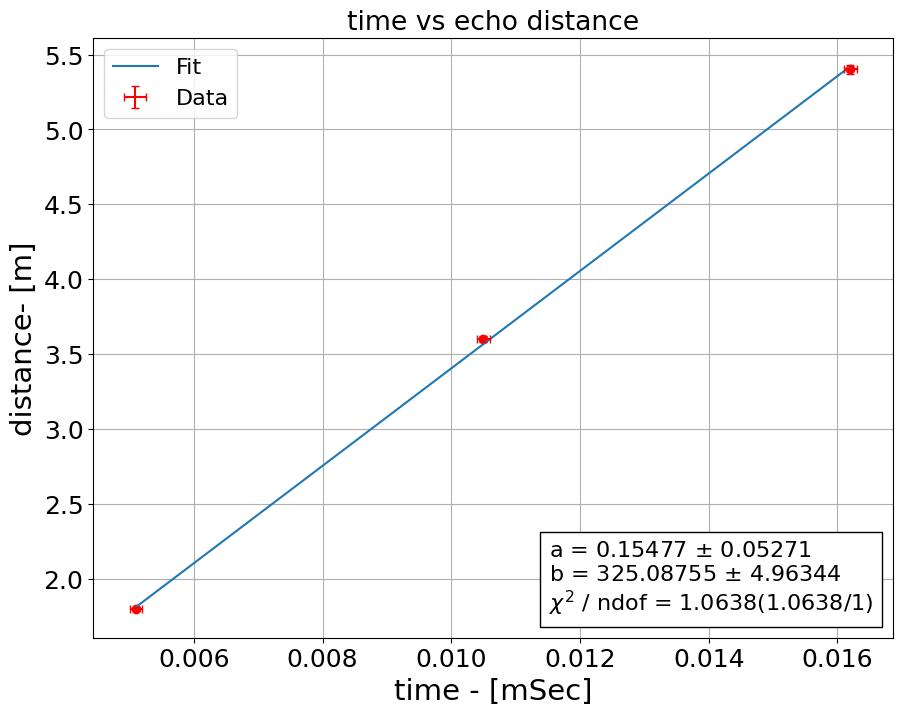

In [30]:
mean_fun = lambda x,a: a +x*0
distance_fun = lambda x,c,R : c/((x+R)**2)
linear_fun = lambda x,a,b: a +x*b
exp_fun    = lambda x,a,b,c: a*np.exp(x*b) +c
power_fun  = lambda x,a,b,c: a*x**b + c
inverce_power_fun = lambda x,a,b: a/(x**2) + b
parab_fun  = lambda x,a,b,c: a*x**2 + b*x + c
gaus_fun   = lambda x,a,b,c,d: [d + a*np.exp(-(x-b)**2/(2*c**2))]
gaus_sin_fun = lambda x,a,b: a*((np.sin(x*b)/(x*b))**2)
double_slit_fun = lambda x,a,b,c: a*((np.sin((np.pi*slit_withe*x/wave_len)-c)/((np.pi*slit_withe*x/wave_len)-c))**2)*(np.cos((np.pi*b*x)/wave_len)**2)
kituv_pi = lambda x,a,b,c : b + a*((np.tan((x-c)-(np.arcsin(np.sin(x-c)/1.5)))**2)/(np.tan((x-c)+(np.arcsin(np.sin(x-c)/1.5)))**2))
kituv_sigma = lambda x,a,b,c : b + a*((np.sin((x-c)-(np.arcsin(np.sin(x-c)/1.5)))**2)/(np.sin((x-c)+(np.arcsin(np.sin(x-c)/1.5)))**2))
ltest = Chi2Reg(linear_fun, measured_x, measured_y, x_uncertainties, y_uncertainties)

#Feed the regression object we just made to Minuit
lopt = Minuit(ltest,a=1,b=1) #the syntax is similar the same as when using Chi2Regression or any other function that Minuit works with, i.e. you could put limits etc here also

#Run the minimization
lopt.migrad()
ltest.show(lopt, goodness_loc=4, x_title= "time - [mSec]", y_title="distance- [m]",metric="chi2",show_grid=True,plot_title="time vs echo distance")

In [ ]:
#show a and b values
print(lopt.values)
d = 2*65*1e-3*lopt.values['b']
print("d =", d)

<ValueView a=-0.0008890811070074792 b=658776096.8121554>
d = 85640892.5855802


## Interpolation, extrapolation and inverse prediction

`reg.predict(opt, x_new)` evaluates the fitted function at any `x_new` (a number or an array) and returns `(y, sigma_y)`.
Inside the data range this is interpolation, outside it is extrapolation. `sigma_y` is the uncertainty of the **fitted curve**, propagated from the full covariance matrix of the parameters (so correlations between e.g. `a` and `b` are included):

$$\sigma_y^2 = J\,C\,J^T,\qquad J_i = \frac{\partial f}{\partial p_i}$$

Note that the uncertainty grows quickly the further you extrapolate.

In [ ]:
# value of the fit at a single point (here: extrapolation to x = 0)
y0, dy0 = ltest.predict(lopt, 0.0)
print("f(0) =", fmt_pm(y0, dy0, latex=False))

# several points at once
x_new = np.array([8e-3, 13e-3, 25e-3])
y_new, dy_new = ltest.predict(lopt, x_new)
for xi, yi, dyi in zip(x_new, y_new, dy_new):
    print(f"f({xi:g}) =", fmt_pm(yi, dyi, latex=False))

`show()` can draw the fit beyond the data with `x_range=(xmin, xmax)` (the extrapolated part is dashed) and the ±1σ confidence band with `show_band=True`:

In [ ]:
ltest.show(lopt, x_range=(0, 25e-3), show_band=True, goodness_loc=4, legend_loc="upper left",
           x_title="time - [mSec]", y_title="distance- [m]", show_grid=True)

### Inverse prediction

`reg.inverse_predict(opt, y_target, dy_target=0, x_range=None)` finds every `x` in `x_range` (default: the data range) where the fitted function equals `y_target`. It returns two arrays `(x, sigma_x)`, because a non-monotonic model can cross `y_target` more than once. The uncertainty is

$$\sigma_x = \frac{\sqrt{\sigma_f(x)^2 + \sigma_{target}^2}}{|f'(x)|}$$

At an extremum `f'(x) ≈ 0`, so `σ_x` blows up there – a warning is printed in that case.

In [ ]:
# x where the fit equals y = 3.0 (inside the data range)
x_sol, dx_sol = ltest.inverse_predict(lopt, y_target=3.0)
for xs, dxs in zip(x_sol, dx_sol):
    print("x =", fmt_pm(xs, dxs, latex=False))

# outside the data -> give a wider x_range; y_target may have its own uncertainty
x_sol, dx_sol = ltest.inverse_predict(lopt, y_target=7.0, dy_target=0.05, x_range=(0, 30e-3))
for xs, dxs in zip(x_sol, dx_sol):
    print("x =", fmt_pm(xs, dxs, latex=False))

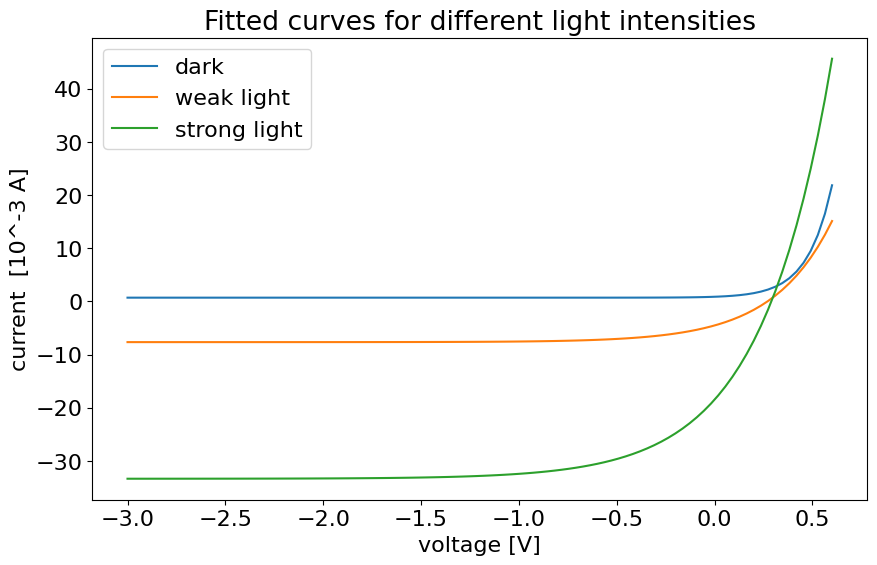

In [ ]:
stats1 = [0.16994655196913364,8.037985820805131,0.718927545475817]
stats2 =[3.1360509184497776,3.3037429925215527,-7.6400876460906115] 
stats3 =[14.8808555190975,2.781469502965639,-33.32363035335445]
all_states = [stats1,stats2,stats3]
labels = ['dark','weak light','strong light']
def exp_fun(x,a,b,c): return a*np.exp(x*b) +c
x=np.linspace(-3,0.6,100)
plt.figure(figsize=(10,6))
for i,stats in enumerate(all_states):
    y=exp_fun(x,stats[0],stats[1],stats[2])
    plt.plot(x,y,label=labels[i])
plt.legend()
plt.xlabel('voltage [V]')
plt.ylabel('current  [10^-3 A]')
plt.title('Fitted curves for different light intensities')
plt.show()

In [ ]:
x_space = np.linspace(measured_x[0],measured_x[-1],1000)
y_sigma = kituv_sigma(x_space,*[lopt.values[p] for p in lopt.parameters])

plt.plot(x_space,y_messured,label="Fit")
plt.plot(x_space,y_predict,label="True")
plt.scatter(measured_x,measured_y,c="red")
plt.errorbar(measured_x,measured_y,y_uncertainties,x_uncertainties,fmt='none',ecolor='red',capsize=3,label="Data")
plt.xlabel("theta (rad)")
plt.ylabel("R_sigma")
plt.legend()
plt.grid()
plt.show()

TypeError: <lambda>() missing 1 required positional argument: 'c'

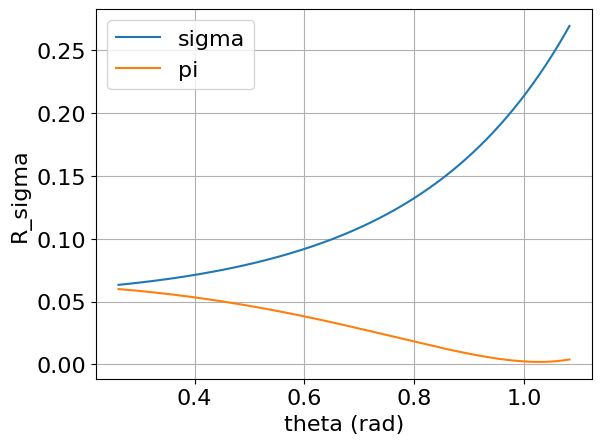

In [ ]:
plt.plot(x_space,y_sigma,label="sigma")
plt.plot(x_space,y_pi,label="pi")
plt.xlabel("theta (rad)")
plt.ylabel("R_sigma")
plt.legend()
plt.grid()
plt.show()

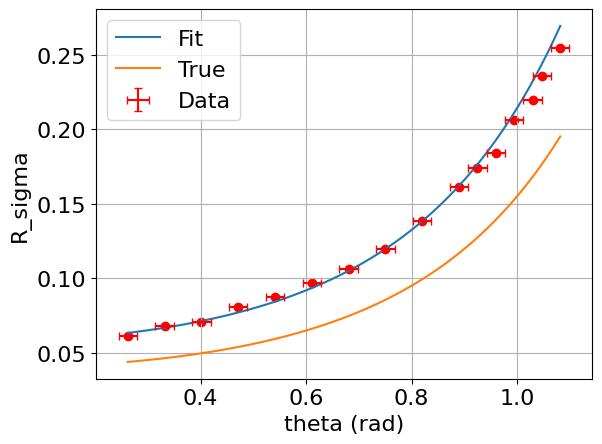

In [ ]:
## plot the graph of lopt in blue , the date point and the graph of the function that was fitted to the data in range of the data in the same graph
x_space = np.linspace(measured_x[0],measured_x[-1],1000)
y_messured = kituv_sigma(x_space,*[lopt.values[p] for p in lopt.parameters])
y_predict = kituv_sigma(x_space,1,0,0)
plt.plot(x_space,y_messured,label="Fit")
plt.plot(x_space,y_predict,label="True")
plt.scatter(measured_x,measured_y,c="red")
plt.errorbar(measured_x,measured_y,y_uncertainties,x_uncertainties,fmt='none',ecolor='red',capsize=3,label="Data")
plt.xlabel("theta (rad)")
plt.ylabel("R_sigma")
plt.legend()
plt.grid()
plt.show()






In [ ]:
y_predict_0 = kituv_sigma(0.00000001,* [lopt.values[p] for p in lopt.parameters])
print(y_predict_0)

0.05706712149530738


In [ ]:
# Find the index of the minimum y value
min_index = np.argmin(y_messured)

# Get the corresponding x and y values
min_x = np.rad2deg(x_range[min_index])
min_y = y_values[min_index]

print(f"Minimum point: x = {min_x}, y = {min_y}")

Minimum point: x = 58.13213213213214, y = 0.5068165645626452


In [ ]:
##find the minimum of the fit tunction 
from scipy.signal import argrelextrema

lopt.minos()    #this will calculate the errors
print(lopt.values)



<ValueView a=1.125527439483491 b=0.011874518670197471 c=-0.0533987490932774>


Finally, we plot the results using the show method:

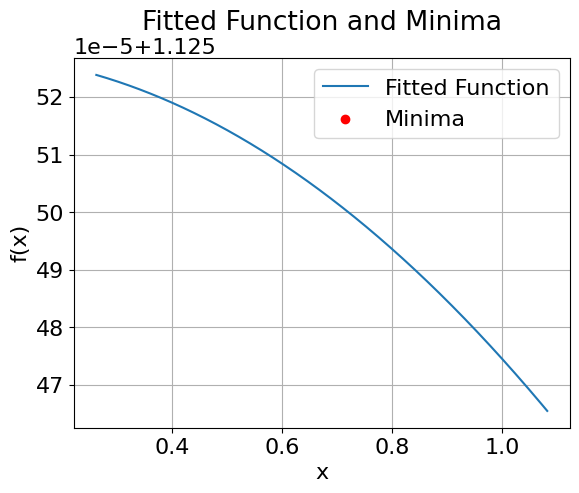

Minima Points:


In [ ]:

from scipy.signal import argrelextrema

# Extract best-fit parameters from Minuit
a_opt = lopt.values['a']
b_opt = lopt.values['b']

# Define the fitted function with optimized parameters
def fitted_function(x):
    return a_opt * ((np.sin(x * b_opt) / (x * b_opt)) ** 2)

# Generate x-values and compute the corresponding y-values
x_range = np.linspace(min(measured_x), max(measured_x), 1000)
y_values = fitted_function(x_range)

# Find indices of local minima
minima_indices = argrelextrema(y_values, np.less)[0]

# Extract the minima points
minima_points = [(x_range[i], y_values[i]) for i in minima_indices]

# Plot the graph
plt.plot(x_range, y_values, label="Fitted Function")
plt.scatter([x[0] for x in minima_points], [x[1] for x in minima_points], color="red", label="Minima")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Fitted Function and Minima")
plt.legend()
plt.grid(True)
plt.show()

# Print the minima
print("Minima Points:")
for i, (x, y) in enumerate(minima_points):
    print(f"Minimum {i + 1}: x = {x:.4f}, y = {y:.4f}")



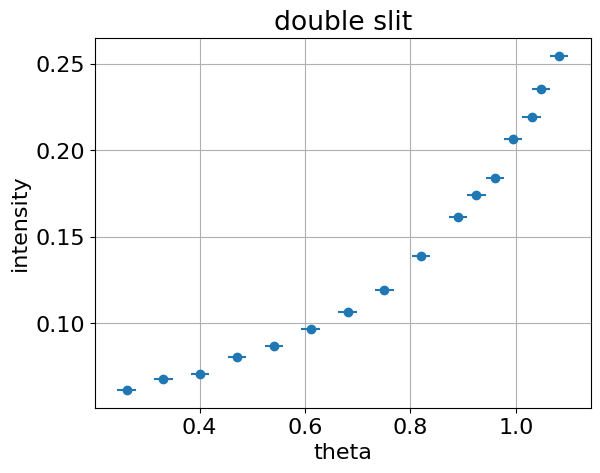

In [ ]:
##plot the x,y values  with axis labels
plt.errorbar(measured_x,measured_y,xerr=x_uncertainties,yerr=y_uncertainties,fmt='o')
plt.xlabel("theta")
plt.ylabel("intensity")
plt.title("double slit")
plt.grid()
plt.show()

And finally let's also account for the uncertainty on our x axis values.  We'll use the same Chi2Reg object but when we supply also x uncertainties it uses the effective variance method (as shown above in the class definition).

Sometimes we want to access our fit results directly (not just see them printed on the graph).  

In [ ]:
#We can simply print them
print(lopt.values)
#Or print by name/index
print("by name ", lopt.values["b"])
print("by index", lopt.values[1])
#same for uncertainties
#Or print by name/index
print("by name ", efvopt.errors["b"])
print("by index", efvopt.errors[1])
#Or maybe more usefully we can put them into variables v for values, u for uncertainties
v = efvopt.values
u = efvopt.errors

#And of course we can print the variables also
print("From our new variables")
print("v = ",v," and u = ",u)
#or a given element at a time, for example uncertainty on b
print(u[1])

<ValueView a=1.125527439483491 b=0.011874518670197471 c=-0.0533987490932774>
by name  0.011874518670197471
by index 0.011874518670197471


NameError: name 'efvopt' is not defined

Let's say we want to take the output of the model and calculate a p-value

In [ ]:
#We can ask for the chi2 value
print(efvopt.fval)
#we can ask for the number of parameters
print(efvopt.nfit)
print ("chi2/ndof = ",efvopt.fval,"/",len(measured_x)-efvopt.nfit," = ", efvopt.fval/(len(measured_x)-efvopt.nfit))
#To caluclate the p-value use chi2.sf(CHI2,NDF)
print("p-value is ",chi2.sf(efvopt.fval,len(measured_x)-efvopt.nfit)) #len(measured_x) means length of measured_x which is the input data, and len(list(efvopt.values))) gives the number of parameters